<a href="https://colab.research.google.com/github/chalanifern/Ridge-Regression-for-Multiple-Linear-Regression/blob/main/Applying_Ridge_Regression_to_House_Price_Prediction_Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [127]:
df = pd.read_csv('/content/Housing.csv')

In [128]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [129]:
df.shape

(545, 13)

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [131]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


Data Cleaning and Preprocessing

In [132]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [133]:
df.isnull().sum().sum()

np.int64(0)

In [134]:
df.duplicated().sum()

np.int64(0)

In [135]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
  print(column, ":", df[column].unique())

mainroad : ['yes' 'no']
guestroom : ['no' 'yes']
basement : ['no' 'yes']
hotwaterheating : ['no' 'yes']
airconditioning : ['yes' 'no']
prefarea : ['yes' 'no']
furnishingstatus : ['furnished' 'semi-furnished' 'unfurnished']


In [136]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,object
guestroom,object
basement,object
hotwaterheating,object
airconditioning,object


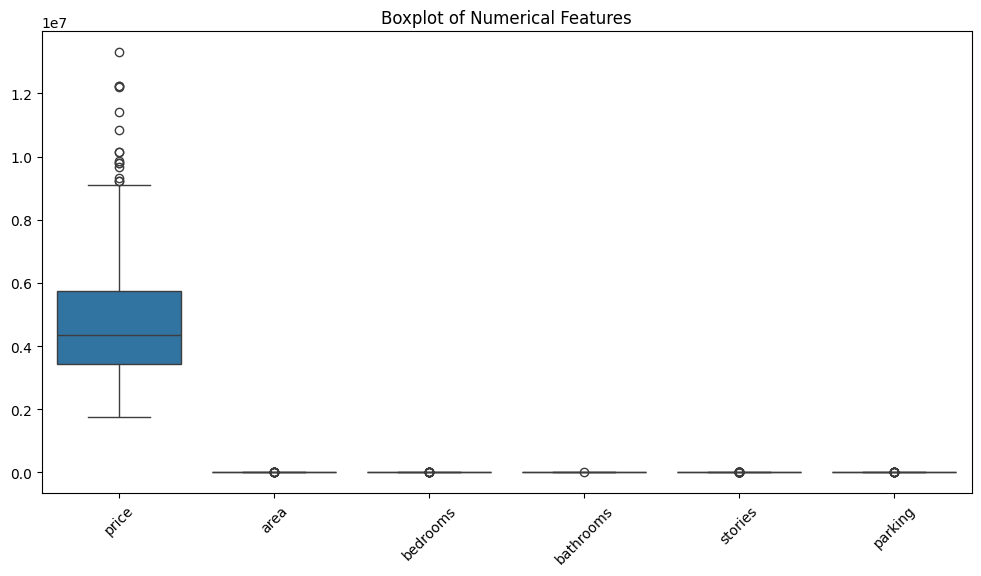

In [137]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df.select_dtypes(include="number"))

plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.show()

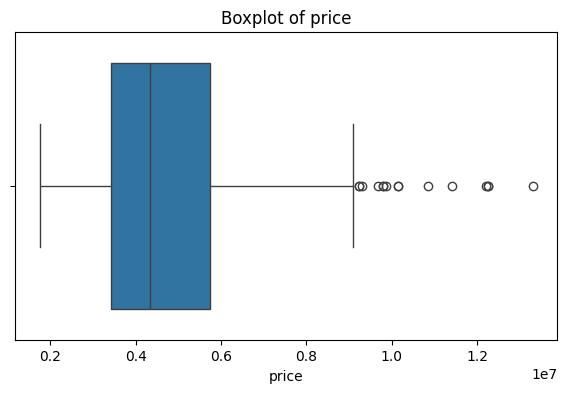

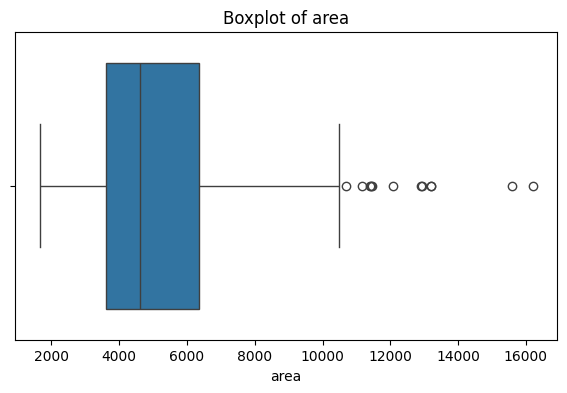

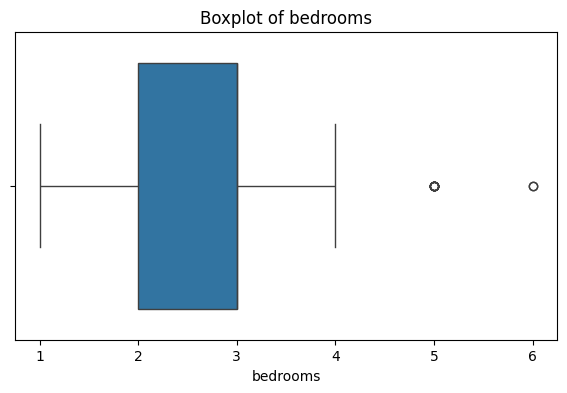

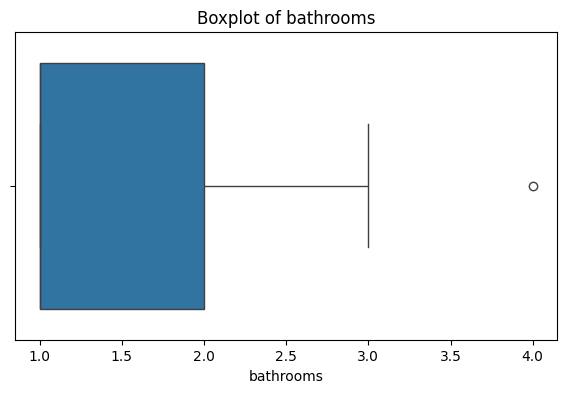

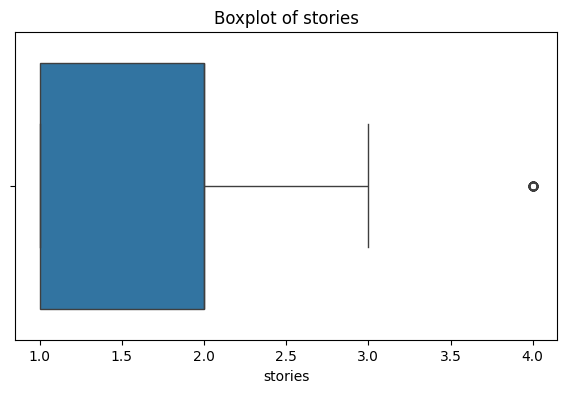

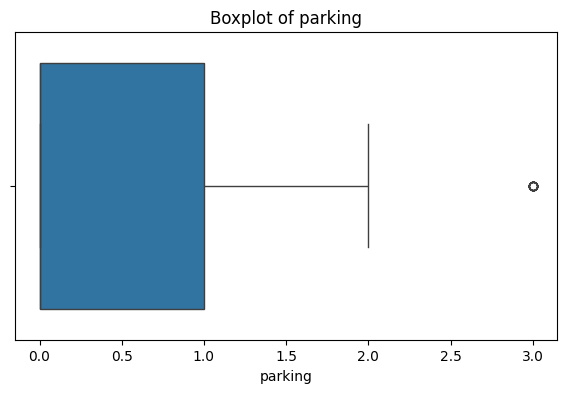

In [138]:
numerical_columns = df.select_dtypes(
    include="number"
).columns

for column in numerical_columns:
  plt.figure(figsize=(7, 4))
  sns.boxplot(x=df[column])
  plt.title(f"Boxplot of {column}")
  plt.show()

Categorical Encoding

In [139]:
binary_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea"
]

for column in binary_columns:
  df[column] = df[column].map({
      "yes": 1,
      "no" : 0
  })

In [140]:
df = pd.get_dummies(
    df,
    columns=["furnishingstatus"],
    drop_first=True,
    dtype=int
)

In [141]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   price                            545 non-null    int64
 1   area                             545 non-null    int64
 2   bedrooms                         545 non-null    int64
 3   bathrooms                        545 non-null    int64
 4   stories                          545 non-null    int64
 5   mainroad                         545 non-null    int64
 6   guestroom                        545 non-null    int64
 7   basement                         545 non-null    int64
 8   hotwaterheating                  545 non-null    int64
 9   airconditioning                  545 non-null    int64
 10  parking                          545 non-null    int64
 11  prefarea                         545 non-null    int64
 12  furnishingstatus_semi-furnished  545 non-null    i

In [143]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,int64
guestroom,int64
basement,int64
hotwaterheating,int64
airconditioning,int64


Exploratory Data Analysis (EDA)

In [144]:
df.describe()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.858716,0.177982,0.350459,0.045872,0.315596,0.693578,0.234862,0.416514,0.326606
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.348635,0.382849,0.477552,0.209399,0.465180,0.861586,0.424302,0.493434,0.469402
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000


Distribution of house prices

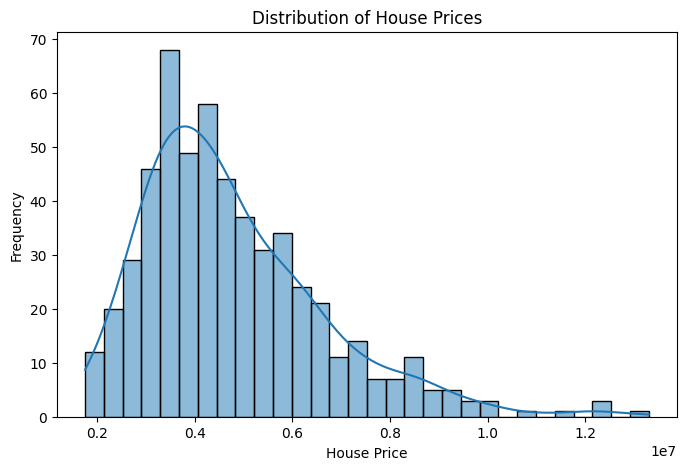

In [145]:
plt.figure(figsize=(8, 5))

sns.histplot(df["price"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

1. Most houses are priced between approximately 3 million and 6 million.

2. The highest concentration appears around 3.5–4 million.

3. There are fewer houses with prices above 8 million.

4. The distribution has a long tail towards the right.

House prices are positively skewed (right-skewed). A relatively small number of expensive houses pull the distribution towards higher values.

Relationship between area and price

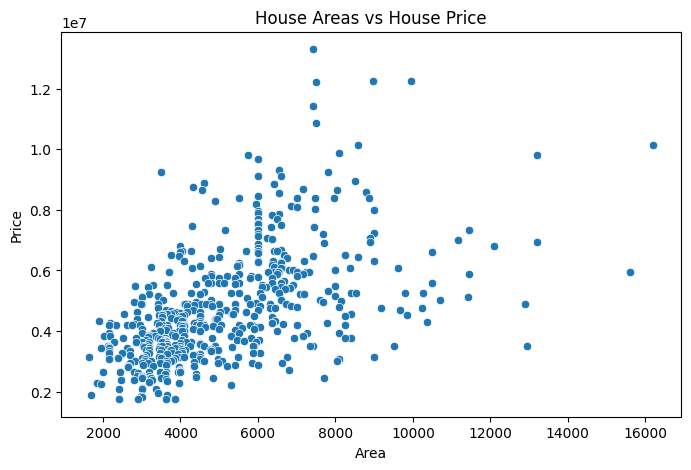

In [146]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="area",
    y="price"
)

plt.title("House Areas vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")

plt.show()

Observations:
1. Smaller houses generally have lower prices.
2. Larger houses generally have higher prices.
3. There is considerable variation in prices among houses with similar areas.
4. Some large houses have relatively low prices compared with other houses of similar size.

This shows area is an important feature, but it cannot explain house prices on its own.

Correlation analysis

In [147]:
correlation = df.corr()

correlation

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
price,1.000000,0.535997,0.366494,0.517545,0.420712,0.296898,0.255517,0.187057,0.093073,0.452954,0.384394,0.329777,0.063656,-0.280587
area,0.535997,1.000000,0.151858,0.193820,0.083996,0.288874,0.140297,0.047417,-0.009229,0.222393,0.352980,0.234779,0.006156,-0.142278
bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,-0.012033,0.080549,0.097312,0.046049,0.160603,0.139270,0.079023,0.050040,-0.126252
bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.042398,0.126469,0.102106,0.067159,0.186915,0.177496,0.063472,0.029834,-0.132107
stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.121706,0.043538,-0.172394,0.018847,0.293602,0.045547,0.044425,-0.003648,-0.082972
mainroad,0.296898,0.288874,-0.012033,0.042398,0.121706,1.000000,0.092337,0.044002,-0.011781,0.105423,0.204433,0.199876,0.011450,-0.133123
guestroom,0.255517,0.140297,0.080549,0.126469,0.043538,0.092337,1.000000,0.372066,-0.010308,0.138179,0.037466,0.160897,0.005821,-0.099023
basement,0.187057,0.047417,0.097312,0.102106,-0.172394,0.044002,0.372066,1.000000,0.004385,0.047341,0.051497,0.228083,0.050284,-0.117935
hotwaterheating,0.093073,-0.009229,0.046049,0.067159,0.018847,-0.011781,-0.010308,0.004385,1.000000,-0.130023,0.067864,-0.059411,0.063819,-0.059194
airconditioning,0.452954,0.222393,0.160603,0.186915,0.293602,0.105423,0.138179,0.047341,-0.130023,1.000000,0.159173,0.117382,-0.053179,-0.094086


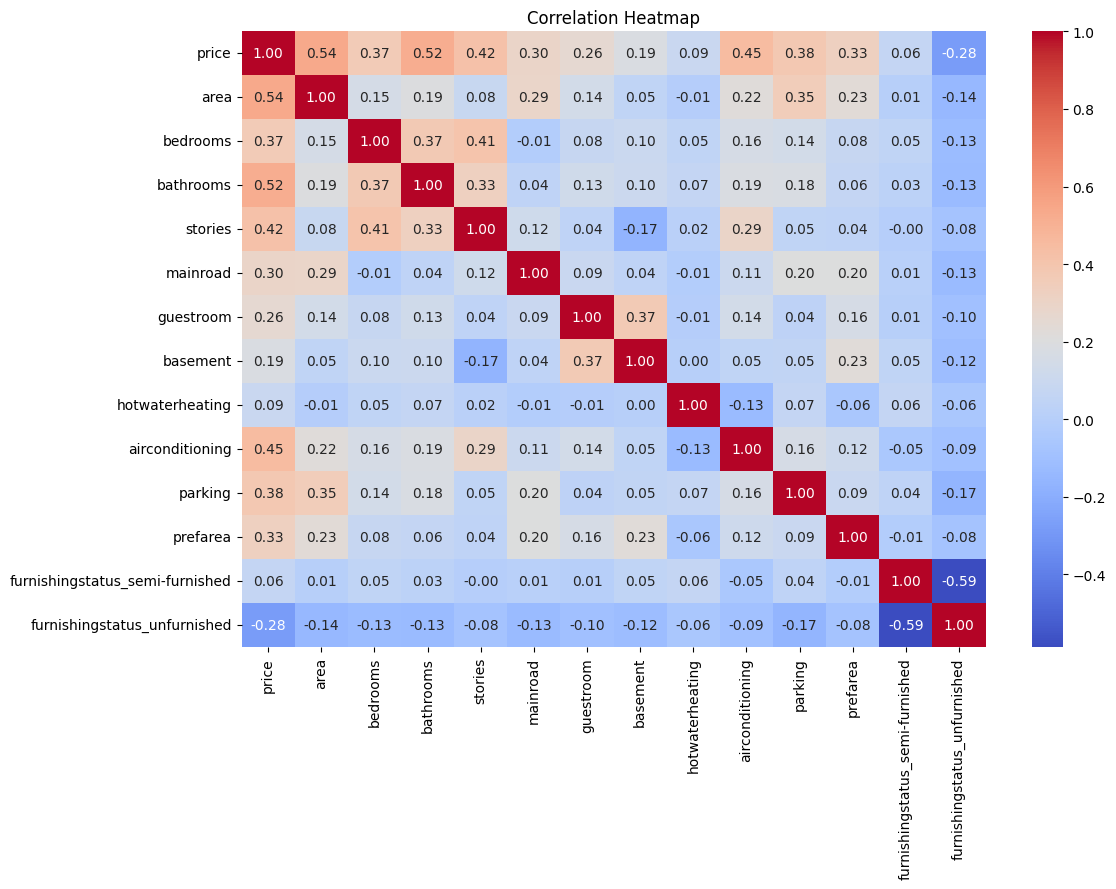

In [148]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Stronger positive relationships with price:
1. Area (0.54)
2. Bathrooms (0.52)
3. Air conditioning (0.45)

Weak positive relationships with price:
1. Hot water heating has a correlation of 0.09, indicating a very weak linear relationship with price.

Negative relationship:
1. Unfurnished has a correlation of -0.28. This indicates that unfurnished houses tend to have lower prices in this dataset.






Preparing data for model training

In [149]:
#Independent Variables
X = df.drop("price", axis=1)

#Dependent Variable
y = df["price"]

In [150]:
print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (545, 13)
Y shape: (545,)


Splitting the Dataset

In [151]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [152]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (436, 13)
X_test: (109, 13)
y_train: (436,)
y_test: (109,)


# Feature Scaling

In [153]:
scalar = StandardScaler()

In [154]:
X_trained_scaled = scalar.fit_transform(X_train)
X_tested_scaled = scalar.transform(X_test)

In [155]:
print("Before scaling:")
print(X_train.head())

print("\nAfter scaling:")
print(pd.DataFrame(
    X_trained_scaled,
    columns=X_train.columns
).head())

Before scaling:
     area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
46   6000         3          2        4         1          0         0   
93   7200         3          2        1         1          0         1   
335  3816         2          1        1         1          0         1   
412  2610         3          1        2         1          0         1   
471  3750         3          1        2         1          0         0   

     hotwaterheating  airconditioning  parking  prefarea  \
46                 0                1        1         0   
93                 0                1        3         0   
335                0                1        2         0   
412                0                0        0         1   
471                0                0        0         0   

     furnishingstatus_semi-furnished  furnishingstatus_unfurnished  
46                                 0                             0  
93                                 1    

In [156]:
print("Feature mean after scaling:")
print(X_trained_scaled.mean(axis=0).round(2))

Feature mean after scaling:
[ 0.  0.  0.  0.  0.  0. -0. -0.  0. -0. -0. -0. -0.]


Train the Ridge Regression Model

In [157]:
ridge_model = Ridge(alpha=1.0)

In [158]:
ridge_model.fit(X_trained_scaled, y_train)

Ridge()

In [159]:
y_pred = ridge_model.predict(X_tested_scaled)

In [166]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5.163036e+06
1,6650000,7.219939e+06
2,3710000,3.111487e+06
3,6440000,4.612737e+06
4,2800000,3.296708e+06
5,4900000,3.533805e+06
6,5250000,5.611263e+06
7,4543000,6.366735e+06
8,2450000,2.725208e+06
9,3353000,2.631239e+06


Model Evaluation

In [161]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 969857.9028478259


In [162]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 1754839327446.8074


In [163]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 1324703.4866138187


In [164]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.6528212603810125


In [165]:
evaluation = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Value": [mae, mse, rmse, r2]
})

evaluation

,Metric,Value
0,MAE,9.698579e+05
1,MSE,1.754839e+12
2,RMSE,1.324703e+06
3,R2 Score,6.528213e-01


Using different Alpha values

In [168]:
alphas = [0.01, 0.1, 1, 10, 100]

results = []

for alpha in alphas:

    model = Ridge(alpha=alpha)

    model.fit(X_trained_scaled, y_train)

    predictions = model.predict(X_tested_scaled)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Alpha": alpha,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df

,Alpha,MAE,MSE,RMSE,R2 Score
0,0.01,970041.533741,1.754324e+12,1.324509e+06,0.652923
1,0.10,970024.715983,1.754370e+12,1.324526e+06,0.652914
2,1.00,969857.902848,1.754839e+12,1.324703e+06,0.652821
3,10.00,968319.372544,1.760078e+12,1.326679e+06,0.651785
4,100.00,972880.827396,1.845931e+12,1.358650e+06,0.634800


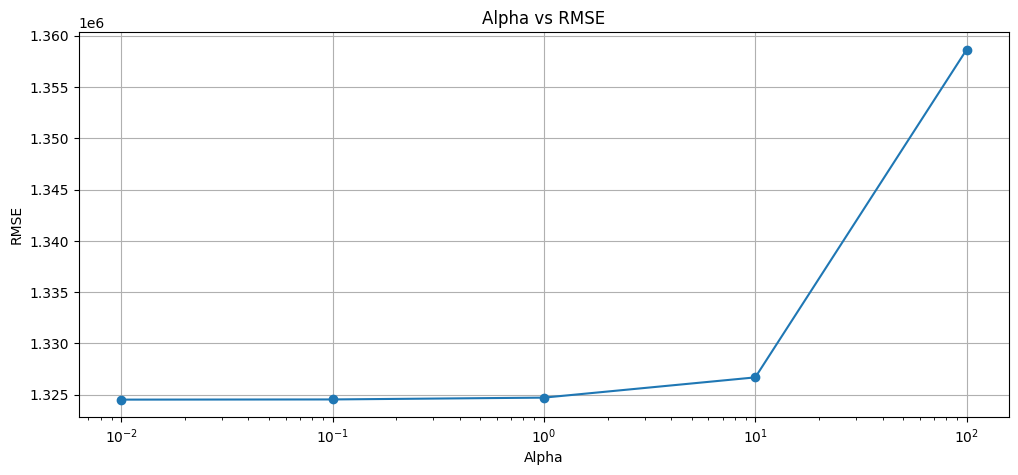

In [169]:
plt.figure(figsize=(12, 5))

plt.plot(
    results_df['Alpha'],
    results_df['RMSE'],
    marker='o'
)

plt.xscale('log')

plt.xlabel('Alpha')
plt.ylabel('RMSE')
plt.title('Alpha vs RMSE')

plt.grid(True)

plt.show()

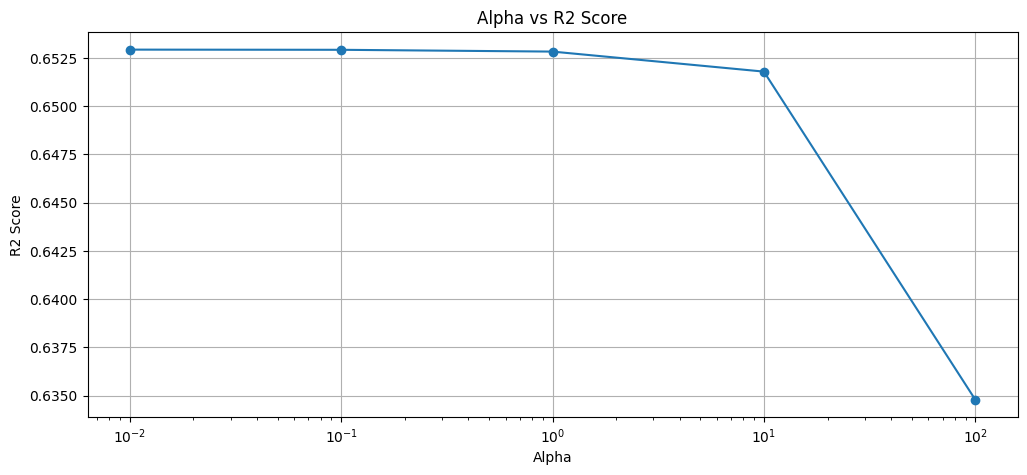

In [170]:
plt.figure(figsize=(12, 5))

plt.plot(
    results_df['Alpha'],
    results_df['R2 Score'],
    marker='o'
)

plt.xscale('log')

plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Alpha vs R2 Score')

plt.grid(True)

plt.show()

In [172]:
# Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_trained_scaled, y_train)

# Train Ridge models
ridge_01 = Ridge(alpha=0.01)
ridge_01.fit(X_trained_scaled, y_train)

ridge_10 = Ridge(alpha=10)
ridge_10.fit(X_trained_scaled, y_train)

ridge_100 = Ridge(alpha=100)
ridge_100.fit(X_trained_scaled, y_train)

Ridge(alpha=100)

In [173]:
coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Linear Regression': linear_model.coef_,
    'Ridge Alpha 0.01': ridge_01.coef_,
    'Ridge Alpha 10': ridge_10.coef_,
    'Ridge Alpha 100': ridge_100.coef_
})

coefficients_df

,Feature,Linear Regression,Ridge Alpha 0.01,Ridge Alpha 10,Ridge Alpha 100
0,area,519552.416340,519541.927729,509401.793450,439402.472521
1,bedrooms,57349.559419,57358.151670,65468.492244,109995.795745
2,bathrooms,521879.027748,521869.124281,512233.181762,443209.531334
3,stories,349251.438906,349243.924460,342064.428395,296080.097481
4,mainroad,128498.628215,128501.540036,131197.799232,143049.181530
5,guestroom,88768.667686,88772.355315,92210.696607,108933.657931
6,basement,187067.803214,187062.531693,182061.360505,151944.401465
7,hotwaterheating,149862.702991,149859.044248,146279.666243,119965.245822
8,airconditioning,365157.393851,365153.808637,361560.703860,330444.912376
9,parking,192005.953667,192007.544415,193454.978873,197704.817692


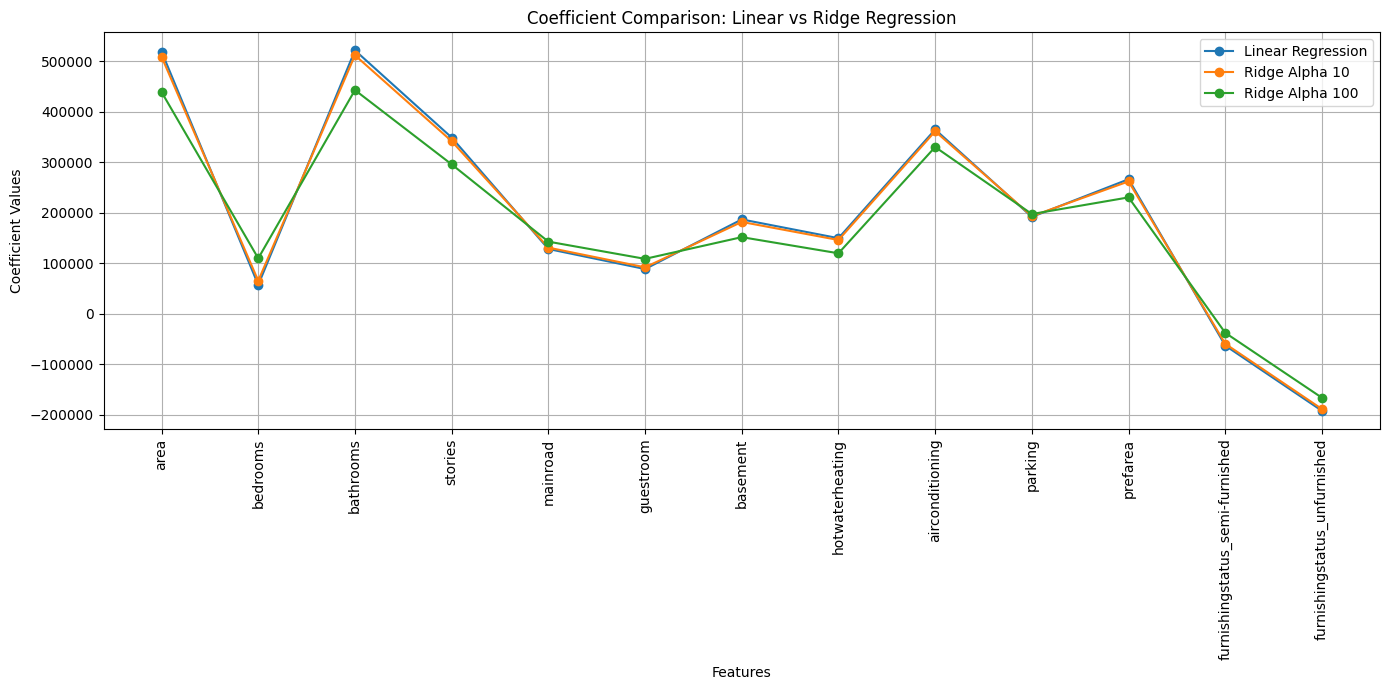

In [174]:
plt.figure(figsize=(14, 7))

plt.plot(
    coefficients_df['Feature'],
    coefficients_df['Linear Regression'],
    marker='o',
    label='Linear Regression'
)

plt.plot(
    coefficients_df['Feature'],
    coefficients_df['Ridge Alpha 10'],
    marker='o',
    label='Ridge Alpha 10'
)

plt.plot(
    coefficients_df['Feature'],
    coefficients_df['Ridge Alpha 100'],
    marker='o',
    label='Ridge Alpha 100'
)

plt.xlabel('Features')
plt.ylabel('Coefficient Values')

plt.title('Coefficient Comparison: Linear vs Ridge Regression')

plt.xticks(rotation=90)

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [175]:
print("Linear Regression:",
      np.linalg.norm(linear_model.coef_))

print("Ridge Alpha 10:",
      np.linalg.norm(ridge_10.coef_))

print("Ridge Alpha 100:",
      np.linalg.norm(ridge_100.coef_))

Linear Regression: 1015644.3272119422
Ridge Alpha 10: 999728.2483816087
Ridge Alpha 100: 888601.3531112606
